In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

HOTPOT_CSV = os.getenv("HOTPOT_CSV")
GSM8K_CSV = os.getenv("GSM8K_CSV")

if not HOTPOT_CSV or not GSM8K_CSV:
    raise ValueError("Dataset paths are not configured.")

hotpot = pd.read_csv(HOTPOT_CSV)
gsm8k = pd.read_csv(GSM8K_CSV)

hotpot.columns = hotpot.columns.str.strip().str.lower()
gsm8k.columns = gsm8k.columns.str.strip().str.lower()

In [2]:

COLORS = {
    "Baseline": "#18214F",   # Dark blue
    "ReAct": "#00B2CE",      # Cyan
    "Reflexion": "#9A79D0",  # Light purple
    "Hybrid": "#6648B1",     # Purple
}

AGENTS = ["Baseline", "ReAct", "Reflexion", "Hybrid"]

sns.set_theme(style="whitegrid", context="talk")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "savefig.facecolor": "white",
    "font.family": "DejaVu Sans",
})

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

def save_figure(name):
    plt.savefig(OUTPUT_DIR / f"{name}.png",
                dpi=300, bbox_inches="tight")
    plt.savefig(OUTPUT_DIR / f"{name}.pdf",
                bbox_inches="tight")
    plt.show()


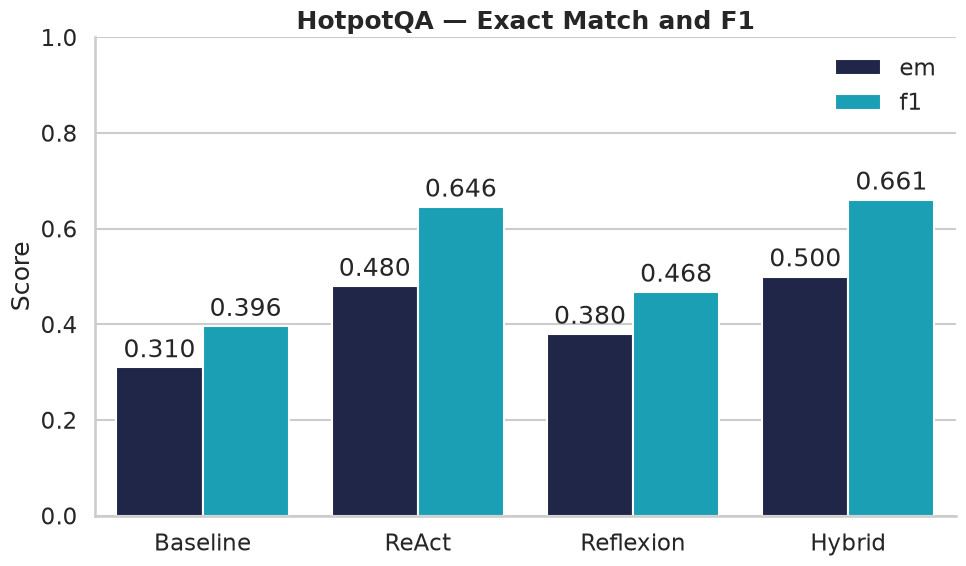

In [3]:

metrics = hotpot[["agent", "em", "f1"]].melt(
    id_vars="agent",
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=metrics,
    x="agent",
    y="Score",
    hue="Metric",
    palette=["#18214F", "#00B2CE"],
    order=AGENTS
)

ax.set_title("HotpotQA — Exact Match and F1",
             fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.legend(title="", frameon=False)
plt.tight_layout()
save_figure("hotpotqa_em_f1")


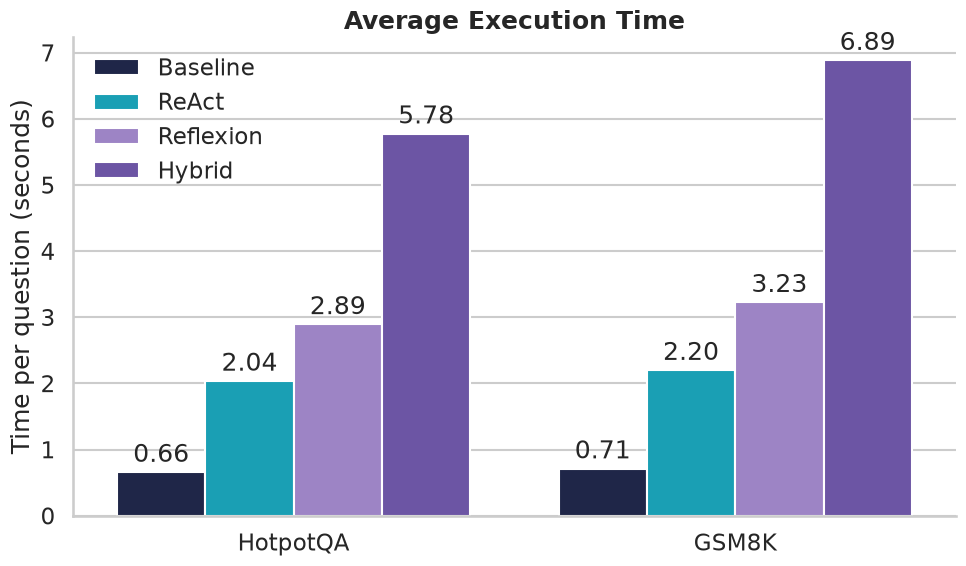

In [4]:

time_df = pd.concat([
    hotpot.assign(Benchmark="HotpotQA"),
    gsm8k.assign(Benchmark="GSM8K")
], ignore_index=True)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=time_df,
    x="Benchmark",
    y="avg_time",
    hue="agent",
    hue_order=AGENTS,
    palette=COLORS
)

ax.set_title("Average Execution Time",
             fontweight="bold")
ax.set_ylabel("Time per question (seconds)")
ax.set_xlabel("")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.legend(title="", frameon=False)
plt.tight_layout()
save_figure("execution_time")


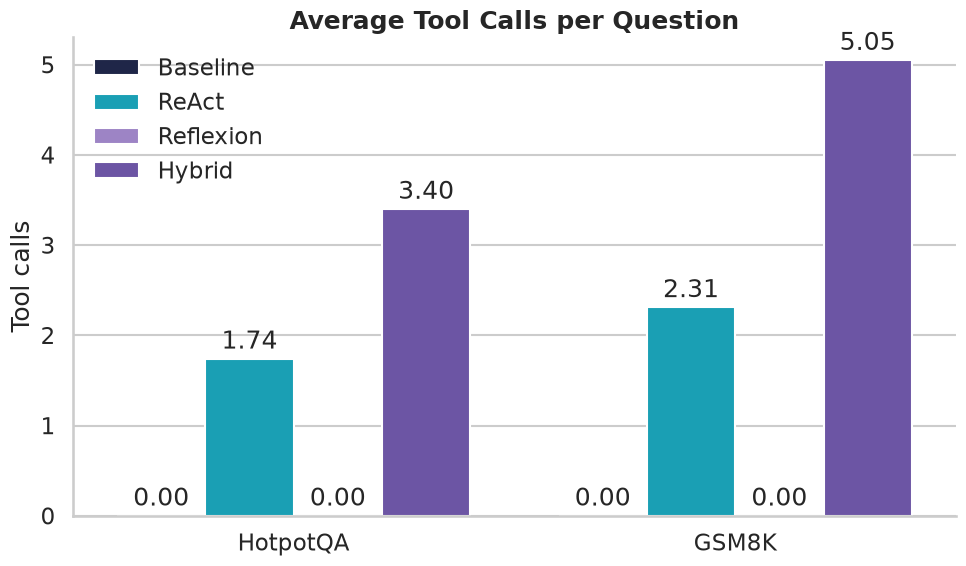

In [5]:

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=time_df,
    x="Benchmark",
    y="avg_tool_calls",
    hue="agent",
    hue_order=AGENTS,
    palette=COLORS
)

ax.set_title("Average Tool Calls per Question",
             fontweight="bold")
ax.set_ylabel("Tool calls")
ax.set_xlabel("")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

plt.legend(title="", frameon=False)
plt.tight_layout()
save_figure("tool_calls")
